# Sensor Realism and Calibration Study

**Study ID:** `sensor_realism_validation_v1`  
**Status:** Baseline implementation checks; hardware calibration pending.  
**Purpose:** Record representative hardware, parameter evidence, and controlled sensor behavior before further policy training.

This study does not train a driving agent. Passing these checks establishes consistency with the current implementation, **not real-world sensor accuracy**. No hardware models or external sources have been selected yet. All current numerical sensor/weather assumptions remain uncalibrated.

Run top to bottom with **Python (final_project HighwayEnv)**. Edit the evidence records and research notes as supporting material becomes available; save each revised run separately.

## 1. Study protocol

| Question | Controlled scenario | Measurements | Evidence needed for realism |
|---|---|---|---|
| Can a sensor detect an approaching vehicle? | One target ahead, ego 25 m/s, target 15 m/s; repeated trials at known separations | Detection fraction, range error, radar closing-velocity error | Detection/error curves for representative hardware and target conditions |
| How does fog affect sensing? | Same target geometry, fixed 40 m separation, severity sweep | Detection fraction by modality/severity | Visibility or extinction measurements matched to hardware tests |
| What happens after shutdown? | Radar on for 0.25 s, then off; fixed scene | Packet cancellation, capture age, map support, power/energy | Device startup/shutdown and processing-pipeline measurements |

Choose empirical acceptance criteria **before calibration**. The notebook's assertions below check implementation rules only. Synthetic simulator truth is used exclusively for diagnostic checks; no policy consumes it.

Limitations: one unobstructed target, no clutter in the diagnostic trials, no sensor correlations, no material/contrast variation, and no physical image/event/waveform rendering. The fog severity scale is abstract and has no calibrated mapping to visibility in meters.

In [1]:
from pathlib import Path
import sys, copy, json, platform
from dataclasses import asdict
from datetime import datetime
from zoneinfo import ZoneInfo
from importlib.metadata import version
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
                    if (p / "environments/sensor_highway/env.py").exists())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from environments.sensor_highway import ExperimentConfig, WeatherConfig
from environments.sensor_highway.backend import VehicleTruth, Scene
from environments.sensor_highway.sensors import SensorSuite
from environments.sensor_highway.weather import WeatherModel, EFFECTS
from environments.sensor_highway.grid import GridBuilder

STUDY_ID = "sensor_realism_validation_v1"
SEED = 42
TRIALS = 300
DISTANCES_M = [10, 20, 40, 60, 100, 160]
FOG_SEVERITIES = [0.0, 0.35, 0.7, 1.0]
# Optional: reload an evidence register edited/saved from an earlier run.
EVIDENCE_CSV = None
config = ExperimentConfig()
config.validate()
print("Interpreter:", sys.executable)
print("Study:", STUDY_ID)


Interpreter: .venv/bin/python
Study: sensor_realism_validation_v1


## 2. Inventory and evidence register

The inventory below comes directly from the current configuration. A representative forward sensor of each modality is used in the controlled checks; the full installed array is preserved in the saved configuration.

Edit `hardware_candidates` to record a manufacturer/model, exact source URL, revision/date, and relevant operating conditions. A specification for a bare sensor does not automatically validate the power of its processing pipeline or the probability of detecting a vehicle.

The parameter register starts with every installed sensor setting plus weather/grid assumptions marked **assumed / unreviewed**. Code/configuration identifies where a value is implemented; it is not empirical evidence. Reviewing a source does not change the simulation automatically—record any proposed value, then deliberately change and rerun the configuration.

In [2]:
inventory = pd.DataFrame([asdict(s) for s in config.sensors])
hardware_candidates = pd.DataFrame([
    {"kind": kind, "manufacturer_model": "TBD", "source_url": "",
     "source_revision_date": "", "operating_conditions": "",
     "selection_rationale": "", "review_status": "not selected"}
    for kind in ["rgb", "event", "radar", "lidar"]])
rows = []
for sensor in config.sensors:
    for parameter, value in asdict(sensor).items():
        if parameter not in {"name", "kind"}:
            rows.append({"component": sensor.name, "parameter": parameter, "current_value": str(value)})
for component, values in [("weather", asdict(config.weather)), ("grid", asdict(config.grid))]:
    rows.extend({"component": component, "parameter": key, "current_value": str(value)}
                for key, value in values.items())
for preset, effects in EFFECTS.items():
    for kind, values in effects.items():
        for parameter, value in zip(["detection_factor", "range_factor", "noise_factor", "clutter_factor"], values):
            rows.append({"component": f"weather.{preset}.{kind}", "parameter": parameter, "current_value": str(value)})
evidence_register = pd.DataFrame(rows).assign(
    evidence_status="assumed / unreviewed", source_url="", source_revision_date="",
    operating_conditions="", proposed_value="", uncertainty_or_range="",
    empirical_acceptance_criterion="", notes="")
if EVIDENCE_CSV is not None:
    evidence_register = pd.read_csv(EVIDENCE_CSV).fillna("")
display(inventory)
display(hardware_candidates)
display(evidence_register.head(15))
print("Parameter records:", len(evidence_register))


,name,kind,heading_deg,fov_deg,range_m,rate_hz,latency_s,warmup_s,power_w,standby_w,detection_probability,range_std_m,bearing_std_deg,radial_velocity_std_m_s,false_positive_rate_hz
0,rgb_N,rgb,0,100,100,20,0.08,0.1,8,0.1,0.95,1.0,1.0,0.5,0.1
1,rgb_NE,rgb,45,100,100,20,0.08,0.1,8,0.1,0.95,1.0,1.0,0.5,0.1
2,rgb_E,rgb,90,100,100,20,0.08,0.1,8,0.1,0.95,1.0,1.0,0.5,0.1
3,rgb_SE,rgb,135,100,100,20,0.08,0.1,8,0.1,0.95,1.0,1.0,0.5,0.1
4,rgb_S,rgb,180,100,100,20,0.08,0.1,8,0.1,0.95,1.0,1.0,0.5,0.1
5,rgb_SW,rgb,225,100,100,20,0.08,0.1,8,0.1,0.95,1.0,1.0,0.5,0.1
6,rgb_W,rgb,270,100,100,20,0.08,0.1,8,0.1,0.95,1.0,1.0,0.5,0.1
7,rgb_NW,rgb,315,100,100,20,0.08,0.1,8,0.1,0.95,1.0,1.0,0.5,0.1
8,event_N,event,0,100,60,50,0.02,0.1,3,0.1,0.95,1.0,1.5,0.5,0.1
9,event_NE,event,45,100,60,50,0.02,0.1,3,0.1,0.95,1.0,1.5,0.5,0.1


,kind,manufacturer_model,source_url,source_revision_date,operating_conditions,selection_rationale,review_status
0,rgb,TBD,,,,,not selected
1,event,TBD,,,,,not selected
2,radar,TBD,,,,,not selected
3,lidar,TBD,,,,,not selected


,component,parameter,current_value,evidence_status,source_url,source_revision_date,operating_conditions,proposed_value,uncertainty_or_range,empirical_acceptance_criterion,notes
0,rgb_N,heading_deg,0,assumed / unreviewed,,,,,,,
1,rgb_N,fov_deg,100,assumed / unreviewed,,,,,,,
2,rgb_N,range_m,100,assumed / unreviewed,,,,,,,
3,rgb_N,rate_hz,20,assumed / unreviewed,,,,,,,
4,rgb_N,latency_s,0.08,assumed / unreviewed,,,,,,,
5,rgb_N,warmup_s,0.1,assumed / unreviewed,,,,,,,
6,rgb_N,power_w,8,assumed / unreviewed,,,,,,,
7,rgb_N,standby_w,0.1,assumed / unreviewed,,,,,,,
8,rgb_N,detection_probability,0.95,assumed / unreviewed,,,,,,,
9,rgb_N,range_std_m,1,assumed / unreviewed,,,,,,,


Parameter records: 294


## 3. Approaching-vehicle diagnostic

Each distance is an independent snapshot along a hypothetical approach, not a continuously moving rollout. There is one target, so any returned detection corresponds to that target when clutter is disabled. Repeated stochastic captures estimate the model's detection fraction; binomial standard error is recorded.

These checks deliberately call the internal `_capture` method to isolate geometry/noise from activation timing. Defaults are preserved except `false_positive_rate_hz=0`, recorded as a diagnostic override. The model already decreases detection probability with distance, so passing a range cutoff check confirms code behavior rather than validating that probability curve. Cameras/events produce bearing only; missing range/velocity errors are intentional.

,sensor,kind,distance_m,weather,severity,trials,detections,detection_fraction,binomial_se,range_rmse_m,radial_velocity_rmse_m_s
0,rgb_N,rgb,10,clear,0.0,300,283,0.9433,0.0133,NaN,NaN
1,rgb_N,rgb,20,clear,0.0,300,275,0.9167,0.0160,NaN,NaN
2,rgb_N,rgb,40,clear,0.0,300,239,0.7967,0.0232,NaN,NaN
3,rgb_N,rgb,60,clear,0.0,300,185,0.6167,0.0281,NaN,NaN
4,rgb_N,rgb,100,clear,0.0,300,0,0.0000,0.0000,NaN,NaN
5,rgb_N,rgb,160,clear,0.0,300,0,0.0000,0.0000,NaN,NaN
6,event_N,event,10,clear,0.0,300,277,0.9233,0.0154,NaN,NaN
7,event_N,event,20,clear,0.0,300,256,0.8533,0.0204,NaN,NaN
8,event_N,event,40,clear,0.0,300,46,0.1533,0.0208,NaN,NaN
9,event_N,event,60,clear,0.0,300,0,0.0000,0.0000,NaN,NaN


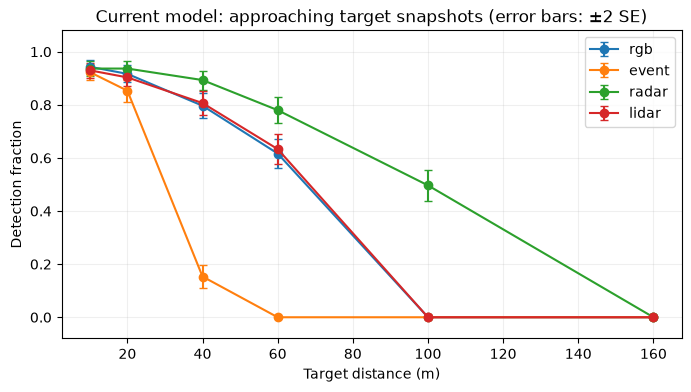

In [3]:
def vehicle(x, speed):
    return VehicleTruth(np.array([x, 0.]), np.array([speed, 0.]), 0., 5., 2.)

representatives = [copy.deepcopy(next(s for s in config.sensors if s.kind == kind))
                   for kind in ["rgb", "event", "radar", "lidar"]]

def capture_trials(sensor, distance, preset="clear", severity=0., seed=SEED):
    sensor = copy.deepcopy(sensor)
    sensor.false_positive_rate_hz = 0
    suite = SensorSuite([sensor], WeatherModel(WeatherConfig(preset=preset, severity=severity),
                        np.random.default_rng(seed)), np.random.default_rng(seed + 1))
    scene = Scene(vehicle(0, 25), (vehicle(distance, 15),))
    detections = [d for _ in range(TRIALS) for d in suite._capture(0, 0., scene).detections]
    count = len(detections)
    fraction = count / TRIALS
    ranges = [d.range_m - distance for d in detections if d.range_m is not None]
    radial = [d.radial_velocity - (-10.) for d in detections if d.radial_velocity is not None]
    return {"sensor": sensor.name, "kind": sensor.kind, "distance_m": distance,
            "weather": preset, "severity": severity, "trials": TRIALS,
            "detections": count, "detection_fraction": fraction,
            "binomial_se": np.sqrt(fraction * (1 - fraction) / TRIALS),
            "range_rmse_m": np.sqrt(np.mean(np.square(ranges))) if ranges else np.nan,
            "radial_velocity_rmse_m_s": np.sqrt(np.mean(np.square(radial))) if radial else np.nan}

approach_results = pd.DataFrame([capture_trials(s, distance)
    for s in representatives for distance in DISTANCES_M])
assert (approach_results.loc[approach_results.distance_m == 160, "detections"] == 0).all()
assert approach_results.loc[approach_results.distance_m == 10, "detections"].gt(0).all()
display(approach_results.round(4))
fig, ax = plt.subplots(figsize=(8, 4))
for kind, group in approach_results.groupby("kind", sort=False):
    ax.errorbar(group.distance_m, group.detection_fraction, yerr=2 * group.binomial_se,
                marker="o", label=kind, capsize=3)
ax.set(xlabel="Target distance (m)", ylabel="Detection fraction",
       title="Current model: approaching target snapshots (error bars: ±2 SE)", ylim=(-.08, 1.08))
ax.legend(); ax.grid(alpha=.2)
plt.show()


## 4. Fog diagnostic

Keep distance at 40 m and relative speed at -10 m/s. Sweep the abstract fog severity while keeping sensor settings fixed. The model imposes reduced range/detection and increased noise/clutter; this isolated experiment suppresses clutter to measure target detections cleanly.

A downward curve is expected by construction. Compare it with hardware measurements before treating it as realistic. RGB and event cameras currently share fog multipliers; that is an assumption to investigate, not a conclusion from this experiment.

,sensor,kind,distance_m,weather,severity,trials,detections,detection_fraction,binomial_se,range_rmse_m,radial_velocity_rmse_m_s
0,rgb_N,rgb,40,fog,0.00,300,239,0.7967,0.0232,NaN,NaN
1,rgb_N,rgb,40,fog,0.35,300,157,0.5233,0.0288,NaN,NaN
2,rgb_N,rgb,40,fog,0.70,300,60,0.2000,0.0231,NaN,NaN
3,rgb_N,rgb,40,fog,1.00,300,0,0.0000,0.0000,NaN,NaN
4,event_N,event,40,fog,0.00,300,46,0.1533,0.0208,NaN,NaN
5,event_N,event,40,fog,0.35,300,19,0.0633,0.0141,NaN,NaN
6,event_N,event,40,fog,0.70,300,0,0.0000,0.0000,NaN,NaN
7,event_N,event,40,fog,1.00,300,0,0.0000,0.0000,NaN,NaN
8,radar_N,radar,40,fog,0.00,300,268,0.8933,0.0178,0.9882,0.5325
9,radar_N,radar,40,fog,0.35,300,267,0.8900,0.0181,1.0476,0.5341


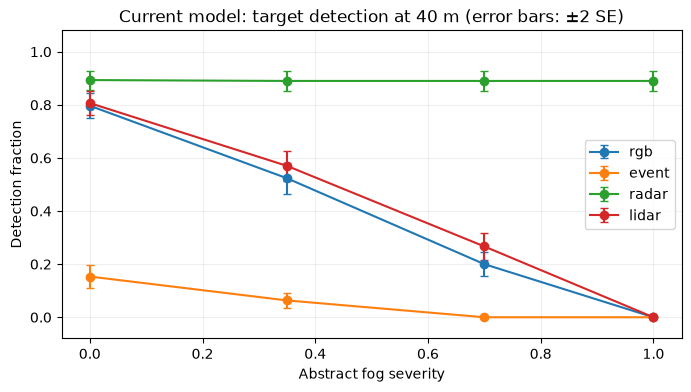

In [4]:
fog_results = pd.DataFrame([capture_trials(s, 40, "fog", severity)
    for s in representatives for severity in FOG_SEVERITIES])
display(fog_results.round(4))
fig, ax = plt.subplots(figsize=(8, 4))
for kind, group in fog_results.groupby("kind", sort=False):
    ax.errorbar(group.severity, group.detection_fraction, yerr=2 * group.binomial_se,
                marker="o", label=kind, capsize=3)
ax.set(xlabel="Abstract fog severity", ylabel="Detection fraction",
       title="Current model: target detection at 40 m (error bars: ±2 SE)", ylim=(-.08, 1.08))
ax.legend(); ax.grid(alpha=.2)
plt.show()


## 5. Shutdown, pending measurements, and stale maps

Turn a forward radar on, then off at 0.25 s. Unlike the capture trials, this check uses the normal `tick` pipeline and its configured warm-up/latency. After shutdown, new acquisitions stop and pending packets are canceled under the current implementation. The latest delivered packet remains available but ages; the mapper discards it at `max_age_s`.

The scene is deliberately stationary across ticks to isolate aging. Radar noise is retained, clutter is disabled. Active/standby energy is integrated at the configured physics frequency. Shutdown cancellation and warm-up are model assumptions requiring hardware evidence.

Pending packets canceled at shutdown: 1
Integrated energy (J): 2.85


,time_s,active,capture_time_s,packet_age_s,pending_packets,max_map_support,total_energy_j
0,0.01,True,NaN,NaN,0,0.0000,0.100
25,0.26,False,0.2,0.06,0,0.9231,2.501
50,0.51,False,0.2,0.31,0,0.6614,2.526
75,0.76,False,0.2,0.56,0,0.4739,2.551
100,1.01,False,0.2,0.81,0,0.3396,2.576
125,1.26,False,0.2,1.06,0,0.2433,2.601
150,1.51,False,0.2,1.31,0,0.1744,2.626
175,1.76,False,0.2,1.56,0,0.1249,2.651
200,2.01,False,0.2,1.81,0,0.0895,2.676
225,2.26,False,0.2,2.06,0,0.0641,2.701


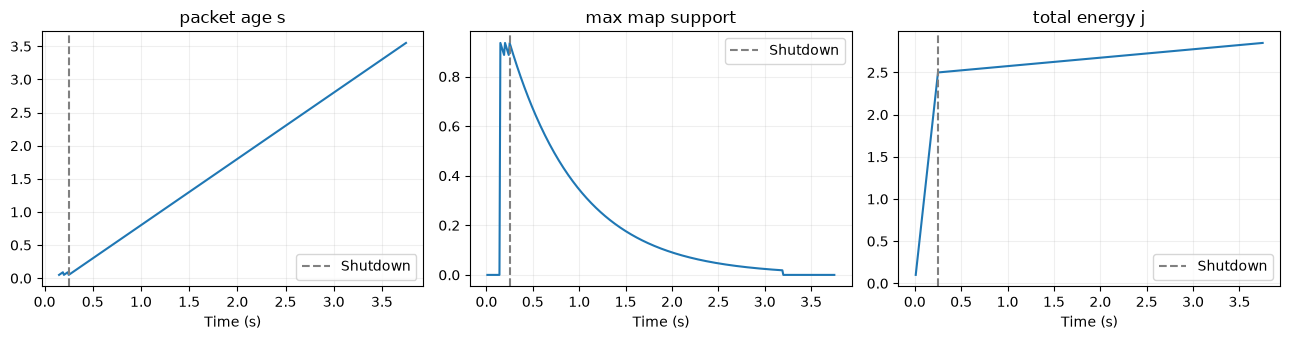

In [5]:
radar = copy.deepcopy(next(s for s in config.sensors if s.kind == "radar"))
radar.false_positive_rate_hz = 0
suite = SensorSuite([radar], WeatherModel(WeatherConfig(preset="clear"),
                    np.random.default_rng(SEED)), np.random.default_rng(SEED + 1))
mapper = GridBuilder(config.grid)
scene = Scene(vehicle(0, 25), (vehicle(20, 15),))
dt = 1 / config.highway["simulation_frequency"]
off_at = 0.25
suite.set_active([1], 0.)
pending_before_shutdown = None
last_capture_at_shutdown = None
shutdown_rows = []
for step in range(1, round((off_at + config.grid.max_age_s + .5) / dt) + 1):
    t = step * dt
    suite.tick(t, dt, scene)
    if step == round(off_at / dt):
        pending_before_shutdown = len(suite.pending)
        assert 0 in suite.latest, "Need a delivered packet before shutdown"
        last_capture_at_shutdown = suite.latest[0].capture_time
        suite.set_active([0], t)
        assert not suite.pending
    packet = suite.latest.get(0)
    grid, uncertainty = mapper.build(suite.latest.values(), scene.ego.position, 0., t, 25)
    shutdown_rows.append({"time_s": t, "active": bool(suite.active[0]),
        "capture_time_s": packet.capture_time if packet else np.nan,
        "packet_age_s": t - packet.capture_time if packet else np.nan,
        "pending_packets": len(suite.pending), "max_map_support": float(grid[1].max()),
        "total_energy_j": suite.total_energy_j})
shutdown_results = pd.DataFrame(shutdown_rows)
after = shutdown_results[shutdown_results.time_s >= off_at]
assert after.capture_time_s.eq(last_capture_at_shutdown).all()
assert after.pending_packets.eq(0).all()
assert shutdown_results.max_map_support.iloc[-1] == 0
expected_energy = radar.power_w * off_at + radar.standby_w * (t - off_at)
assert np.isclose(suite.total_energy_j, expected_energy)
print("Pending packets canceled at shutdown:", pending_before_shutdown)
print("Integrated energy (J):", round(suite.total_energy_j, 4))
display(shutdown_results.iloc[::25].round(4))
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, column in zip(axes, ["packet_age_s", "max_map_support", "total_energy_j"]):
    ax.plot(shutdown_results.time_s, shutdown_results[column])
    ax.axvline(off_at, linestyle="--", color="gray", label="Shutdown")
    ax.set(xlabel="Time (s)", title=column.replace("_", " "))
    ax.grid(alpha=.2); ax.legend()
plt.tight_layout(); plt.show()


## 6. Research log and decisions

Edit the entries below as the study progresses. Keep an observation separate from its interpretation and evidence. Record source URLs/revisions in the evidence register; do not mark a parameter calibrated based only on these synthetic checks.

- **Research date / reviewer:** TBD
- **Selected hardware and selection rationale:** TBD
- **External datasets or bench measurements:** TBD
- **Empirical acceptance criteria, set before tuning:** TBD
- **Calibration/validation split:** TBD
- **Parameters changed and supporting evidence:** TBD
- **Unresolved disagreements or missing measurements:** TBD
- **Decision on suitability for further adaptive-sensing claims:** Pending external evidence.


In [6]:
study_findings = pd.DataFrame([
    {"scenario": "approach", "implementation_status": "range cutoff / near detection checks passed",
     "empirical_status": "pending", "interpretation": "Model detection/error curves recorded; not hardware validated"},
    {"scenario": "fog", "implementation_status": "severity curves recorded",
     "empirical_status": "pending", "interpretation": "Behavior follows assumed fog coefficients"},
    {"scenario": "shutdown", "implementation_status": "cancellation / aging / energy checks passed",
     "empirical_status": "pending", "interpretation": "Current pipeline rules work; hardware timing remains unverified"}
])
display(study_findings)
RESEARCH_NOTES = {
    "reviewer": "TBD", "hardware_selection": "pending", "empirical_acceptance_criteria": "pending",
    "external_validation": "pending", "decision": "Baseline implementation checks only; no realism claim",
    "next_actions": ["Select representative hardware and primary sources",
                     "Record conditions and uncertainty for each parameter",
                     "Define empirical criteria and independent validation scenarios",
                     "Calibrate supported parameters and rerun this study"]
}


,scenario,implementation_status,empirical_status,interpretation
0,approach,range cutoff / near detection checks passed,pending,Model detection/error curves recorded; not har...
1,fog,severity curves recorded,pending,Behavior follows assumed fog coefficients
2,shutdown,cancellation / aging / energy checks passed,pending,Current pipeline rules work; hardware timing r...


## 7. Save the study record

Each execution creates a new timestamped directory containing the configuration, full evidence register, hardware candidates, diagnostic overrides, scenario measurements, findings, research notes, and package/source provenance. Edit the tables/notes above before rerunning this cell to record a review. Models and training results from other experiments are not modified.

In [7]:
import hashlib
stamp = datetime.now(ZoneInfo("America/New_York")).strftime("%Y%m%d_%H%M%S_%f")
output = PROJECT_ROOT / "runs/sensor_studies" / f"sensor_realism_study_{stamp}"
output.mkdir(parents=True, exist_ok=False)
config.save(output / "config.json")
for name, table in {"sensor_inventory": inventory, "hardware_candidates": hardware_candidates,
                    "evidence_register": evidence_register, "approach": approach_results,
                    "fog": fog_results, "shutdown": shutdown_results,
                    "findings": study_findings}.items():
    table.to_csv(output / f"{name}.csv", index=False)
(output / "research_notes.json").write_text(json.dumps(RESEARCH_NOTES, indent=2) + "\n")
source_files = ["environments/sensor_highway/config.py", "environments/sensor_highway/sensors.py",
                "environments/sensor_highway/weather.py", "environments/sensor_highway/grid.py"]
metadata = {"study_id": STUDY_ID, "status": "uncalibrated baseline",
    "seed": SEED, "trials_per_snapshot": TRIALS, "distances_m": DISTANCES_M,
    "fog_severities": FOG_SEVERITIES, "shutdown_time_s": off_at,
    "diagnostic_overrides": {"false_positive_rate_hz": 0, "target_relative_speed_m_s": -10},
    "python": platform.python_version(),
    "package_versions": {name: version(name) for name in ["numpy", "pandas", "matplotlib", "highway-env", "gymnasium"]},
    "source_sha256": {name: hashlib.sha256((PROJECT_ROOT / name).read_bytes()).hexdigest() for name in source_files}}
(output / "metadata.json").write_text(json.dumps(metadata, indent=2) + "\n")
print("Saved study:", output)


Saved study: runs/sensor_studies/sensor_realism_study_20261101_120401_925476


## Follow-up: sensor contribution and range sensitivity

Continue in [Sensor Contribution and Range Sensitivity Study](sensor_contribution_sensitivity_study.ipynb).
It compares measurement availability, removes modalities from a frozen observation-driven driver,
and tests equal/reversed RGB-event range assumptions. Neither study has yet calibrated its
parameters against external hardware measurements.
